# Fiducial PV initial conditions

**Question:** does changing the displacement's handedness produce a detectable change in tetrahedron chirality?

**PV** means parity violation; **helicity** describes the handedness of the displacement field's twisting pattern. Our estimator $\widehat\chi$ is normalized tetrahedron chirality, a dimensionless number in $[-1,1]$ whose sign reverses under reflection ([geometric definition](basic.ipynb)).

**Chirality reminder.** Order each tetrahedron's vertices by increasing $s_i=\sum_{j\ne i}|\mathbf r_i-\mathbf r_j|^2$, then label them $\mathbf r_0,\ldots,\mathbf r_3$. With $\mathbf v_a=\mathbf r_a-\mathbf r_0$ for $a=1,2,3$,
$$
\chi=\mathbf v_1\cdot(\mathbf v_2\times\mathbf v_3),\qquad
\widehat\chi=\frac{\chi}{|\mathbf v_1||\mathbf v_2||\mathbf v_3|}\in[-1,1].
$$
$\chi$ is six times the signed tetrahedron volume; $\widehat\chi$ removes the overall size scale. The ordering makes the sign independent of input vertex labels; tied scores give zero chirality. Reflection reverses both signs. The **catalogue signal** $S_s(\epsilon)$ averages $\widehat\chi$ over tetrahedra (Section 4).

Construct a Gaussian density mesh, derive its Zel'dovich approximation (ZA) displacement, add an independent helical displacement, then place lattice particles using their sum. This follows the initial-condition construction in [Shim et al., Eqs. 1–8](https://arxiv.org/html/2406.06080v2), using our controlled toy spectrum. Gravitational evolution is a later step.

In [1]:
from pathlib import Path
import contextlib, csv, html, io, json, sys
import numpy as np
from IPython.display import display, Markdown, HTML
PROJECT = Path('/home/users/h/hes/projects/2026_DT_Parity')
RUN = Path('/srv/beegfs/scratch/users/h/hes/projects/cosmicPV/20261121_mesh_ic_L1000_N256_fixedIC_10')
sys.path.insert(0, str(PROJECT/"src"))
from parity_study.paths import OUTPUT_ROOT, expose_output, selection_output, independent_ic_output
from parity_study.storage import atomic_json, atomic_npz
from parity_study.summarize import summarize
from parity_study.initial_conditions import cic_density, displace_mesh
OUT = OUTPUT_ROOT/'field_PVdisp'
(OUT/"figures").mkdir(parents=True, exist_ok=True)
expose_output(PROJECT, OUT)
with contextlib.redirect_stdout(io.StringIO()):
    summary = summarize(RUN)
config = json.loads((RUN/"config.json").read_text())
field = config["field"]
validation = json.loads((RUN/"validation/report.json").read_text())
pilot = config.get("purpose") == "technical_pilot"
SELECTION = selection_output(OUT)
has_selection = (SELECTION/"protocol.json").exists()
display(Markdown(f"**{'Discovery ensemble' if has_selection else 'Technical pilot' if pilot else 'Signal scan'}:** "
                 f"{summary['completed_records']}/{summary['expected_records']} saved catalogues; "
                 f"validation **{'passed' if validation['passed'] else 'failed'}**."))
if pilot and not has_selection:
    display(Markdown("**This small run checks the construction and measurement pipeline; it makes no detection claim.**"))
if has_selection:
    selection_protocol = json.loads((SELECTION/"protocol.json").read_text())
    selection_seeds = selection_protocol["confirmation_seeds"]
    display(Markdown("**Sections 1–5:** original displacement seeds 0–9. "
                     f"**Sections 6–7:** tetrahedron selections with **{len(selection_seeds)} realizations** "
                     f"(displacement seeds {selection_seeds[0]}–{selection_seeds[-1]}) at A=2."))
if independent_ic_output(OUT) is not None:
    independent_protocol = json.loads((independent_ic_output(OUT)/"protocol.json").read_text())
    display(Markdown(f"**Section 8:** **{len(independent_protocol['seeds'])} independent Gaussian initial conditions**, "
                     "with the same frozen shape cut and A=2; both density and helical fields vary."))
if not summary["complete"]:
    display(Markdown("**Partial ensemble: results are provisional.**"))
fixed_density = field.get("density_seed") is not None
if fixed_density:
    display(Markdown(f"**Fixed initial condition:** density seed **{field['density_seed']}** "
                     f"sets the Gaussian density and ZA displacement for all **{config['scan']['seeds']}** "
                     "helical-displacement seeds. The lattice is also fixed. "
                     "**Error bars describe displacement variation at this one initial condition.**"))
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi":110,"font.size":10})
def save_figure(fig, name):
    for suffix in ("png", "pdf"):
        fig.savefig(OUT/"figures"/f"{name}.{suffix}", dpi=160, bbox_inches="tight")
    plt.show()
def save_table(rows, name):
    if rows:
        with (OUT/f"{name}.csv").open("w", newline="") as f:
            w = csv.DictWriter(f, fieldnames=list(rows[0]))
            w.writeheader()
            w.writerows(rows)

def show_table(rows, columns):
    """Display a compact table; columns are (dictionary key, displayed heading)."""
    if not rows:
        display(Markdown("No measurements available for this section."))
        return
    def fmt(value):
        if value is None:
            return "—"
        if isinstance(value, (float, np.floating)):
            return f"{value:.5g}"
        return str(value)
    heading = "".join(f"<th>{html.escape(title)}</th>" for _, title in columns)
    body = "".join("<tr>" + "".join(
        f"<td>{html.escape(fmt(row.get(key)))}</td>" for key, _ in columns) + "</tr>"
        for row in rows)
    display(HTML("<div style='overflow-x:auto'><table><thead><tr>" + heading +
                 "</tr></thead><tbody>" + body + "</tbody></table></div>"))

**Discovery ensemble:** 51/51 saved catalogues; validation **passed**.

**Sections 1–5:** original displacement seeds 0–9. **Sections 6–7:** tetrahedron selections with **25 realizations** (displacement seeds 10–34) at A=2.

**Section 8:** **25 independent Gaussian initial conditions**, with the same frozen shape cut and A=2; both density and helical fields vary.

**Fixed initial condition:** density seed **0** sets the Gaussian density and ZA displacement for all **10** helical-displacement seeds. The lattice is also fixed. **Error bars describe displacement variation at this one initial condition.**

## 1. Field first, particles second

$\delta$ is density contrast (density divided by its mean, minus one); $\delta_{\mathbf k}$ is its Fourier mode at wavevector $\mathbf k$, with $k=|\mathbf k|$. GRF means Gaussian random field, $P_\delta$ its power spectrum, and $\boldsymbol\Psi_{\rm ZA}$ its ZA displacement:
$$
\delta_{\bf k}\sim\mathrm{GRF}[P_\delta(k)],\qquad
\boldsymbol\Psi_{{\rm ZA},{\bf k}}=\frac{i\mathbf k}{k^2}\delta_{\bf k},\qquad
-\nabla\cdot\boldsymbol\Psi_{\rm ZA}=\delta.
$$
Our toy shape is $P_\delta\propto k^n e^{-k^2R_\delta^2}$: $n$ is the spectral slope, $R_\delta$ the density smoothing length, and $\sigma_\delta$ the ensemble root mean square (RMS) density contrast.
For the helical displacement, $R_h$ is its smoothing length, $W_{{\rm hel},{\bf k}}$ its normalized mode weight, $P_{\rm hel}$ its power, and $A$ the **displacement strength**:
$$
W_{{\rm hel},{\bf k}}\propto P_\delta(k)e^{-k^2R_h^2}/k^4,\quad
\sum_{\bf k}W_{{\rm hel},{\bf k}}=1,\quad P_{\rm hel}=A^2W_{\rm hel}.
$$
This normalization makes $A$ the ensemble RMS helical displacement, in the same length units as the box; individual realizations fluctuate around this scale.

$\epsilon$ controls the helicity mixture: $+1$ selects the positive-helicity field $\mathbf u_+$, $-1$ selects the negative-helicity field $\mathbf u_-$, and $0$ mixes equal expected power. The independent fields $\mathbf u_\pm$ each have unit ensemble RMS. For initial lattice positions $\mathbf q$, final positions $\mathbf x$, and periodic box side $L$:
$$
\mathbf x=\left[\mathbf q+\boldsymbol\Psi_{\rm ZA}(\mathbf q)
+A\left(\sqrt{\frac{1+\epsilon}{2}}\mathbf u_+(\mathbf q)
+\sqrt{\frac{1-\epsilon}{2}}\mathbf u_-(\mathbf q)\right)\right]\bmod L.
$$
All components are evaluated at the same $\mathbf q$; the scalar and helical fields use independent draws.

In [2]:
show_table([dict(L=field["L"], N=field["N"], particle_grid=field["particle_grid"],
    Ngal=field["Ngal"], sigma=field["sigma_delta"], Rh=field["helical_smoothing"],
    spectrum=str(field["spectrum"]), A=str(config["scan"]["amplitudes"]))],
    [("L","Box L"),("N","Mesh N"),("particle_grid","Particle grid"),("Ngal","Particles"),
     ("sigma","Density RMS σδ"),("Rh","Helical smoothing Rh"),("spectrum","Density spectrum"),("A","Displacement strength A")])
example = next(iter(sorted((RUN/"fields").glob("main_*.npz"))), None)
if example is None:
    raise FileNotFoundError("No saved mesh realization yet; complete a seed block first.")
with np.load(example) as z:
    arrays = {k:z[k] for k in ("q", "za", "plus", "minus", "delta_mesh")}
    meta = json.loads(str(z["metadata_json"]))
display(Markdown(f"**Illustration seed:** {meta['seed']}. The paired catalogues share this density field and particle lattice."))
if fixed_density:
    display(Markdown(f"Density seed **{field['density_seed']}** is held fixed across all displacement seeds."))
kmax = field.get("kmax") or np.pi*min(field["N"],field["particle_grid"])/field["L"]
spacing = field["L"]/field["particle_grid"]
display(Markdown(f"Particle spacing **{spacing:g}**; Fourier cutoff **k_max={kmax:.5g}** "
                 "(limited by both mesh and particle sampling)."))

Box L,Mesh N,Particle grid,Particles,Density RMS σδ,Helical smoothing Rh,Density spectrum,Displacement strength A
1000,256,32,32768,0.2,6.25,"{'kind': 'power_law', 'index': 0.0, 'smoothing': 6.25}","[0.5, 2.0]"


**Illustration seed:** 0. The paired catalogues share this density field and particle lattice.

Density seed **0** is held fixed across all displacement seeds.

Particle spacing **31.25**; Fourier cutoff **k_max=0.10053** (limited by both mesh and particle sampling).

## 2. What does the particle density look like?

The first panel shows the input Gaussian field; the others show densities measured by depositing particles onto the mesh with cloud-in-cell (CIC) interpolation. All panels average the same central slab on a display grid no finer than the particle lattice. Finite displacements can change the final density beyond the linear relation above.

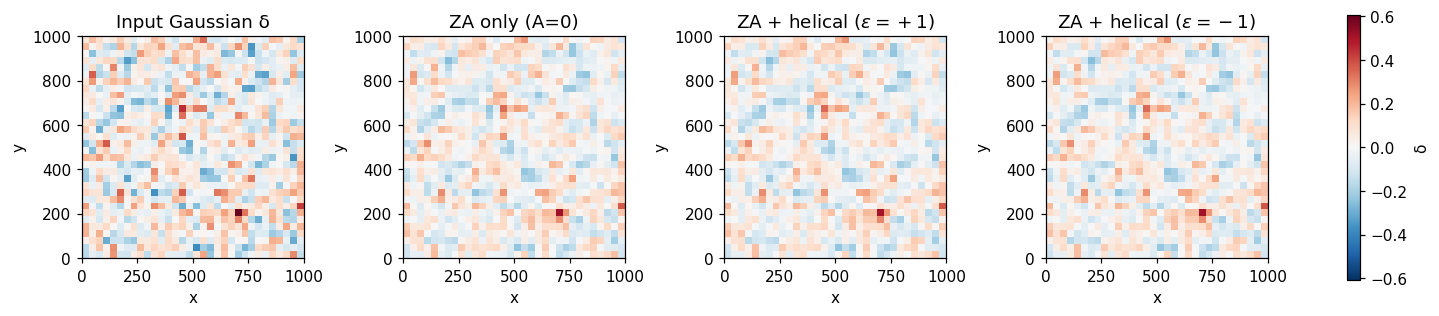

Display grid: **32³**, slab thickness **93.75**; field mesh: **256³**. Displacement strength **A=2**.

In [3]:
L, N = field["L"], field["N"]
A = config["scan"]["amplitudes"][-1]
plot_N = min(N, field["particle_grid"])
if N % plot_N:
    plot_N = max(n for n in range(1,plot_N+1) if N % n == 0)
step = N // plot_N
density = [arrays["delta_mesh"][::step,::step,::step]]
labels = ["Input Gaussian δ"]
for amp,eps,label in [(0.,0.,"ZA only (A=0)"),(A,1.,r"ZA + helical ($\epsilon=+1$)"),(A,-1.,r"ZA + helical ($\epsilon=-1$)")]:
    cat, _ = displace_mesh(arrays, A=amp, eps=eps, L=L)
    density.append(cic_density(cat, L=L, N=plot_N))
    labels.append(label)
slab = slice(max(0,plot_N//2-1), min(plot_N,plot_N//2+2))
panels = [d[:,:,slab].mean(axis=2) for d in density]
lim = max(abs(p).max() for p in panels)
fig, axes = plt.subplots(1,4,figsize=(13,3.3),constrained_layout=True)
for ax,p,label in zip(axes,panels,labels):
    im=ax.imshow(p.T, origin="lower",extent=[0,L,0,L],cmap="RdBu_r",vmin=-lim,vmax=lim)
    ax.set(title=label,xlabel="x",ylabel="y")
fig.colorbar(im,ax=axes,label="δ",shrink=.75)
save_figure(fig,"initial_density_comparison")
display(Markdown(f"Display grid: **{plot_N}³**, slab thickness **{(slab.stop-slab.start)*L/plot_N:g}**; "
                 f"field mesh: **{N}³**. Displacement strength **A={A:g}**."))
atomic_npz(OUT/"example_density_meshes.npz", density=np.stack(density), labels=np.array(labels),
           seed=np.array(meta["seed"]), helical_A=np.array(A), display_N=np.array(plot_N),
           field_N=np.array(N))

## 3. Does the implementation pass its checks?

Check the ZA density relation, the two helicities, particle-mass conservation, and the parity transformation of $\widehat\chi$.

In [4]:
v = validation["field"]
checks = [dict(test="−div ΨZA = δ",value=v["za_density_max_error"],passed=v["za_density_max_error"]<1e-12),
          dict(test="curl ΨZA = 0",value=v["za_curl_max"],passed=v["za_curl_max"]<1e-12),
          dict(test="Positive helicity",value=v["plus"]["normalized_helicity"],passed=abs(v["plus"]["normalized_helicity"]-1)<1e-12),
          dict(test="Negative helicity",value=v["minus"]["normalized_helicity"],passed=abs(v["minus"]["normalized_helicity"]+1)<1e-12),
          dict(test="CIC mean density contrast",value=validation["cic_mean_delta"],passed=abs(validation["cic_mean_delta"])<1e-12),
          dict(test="χ̂ transformation error",value=max(r["absolute_error"] for r in validation["T1"].values()),
               passed=all(r["passed"] for r in validation["T1"].values()))]
audit_path = RUN/"validation/fixed_ic_ensemble.json"
if fixed_density and audit_path.exists():
    audit = json.loads(audit_path.read_text())
    checks.append(dict(test=f"Fixed density/lattice and ZA across {audit['displacement_seeds']} seeds",
                       value=audit["max_za_difference"], passed=audit["passed"]))
show_table(checks,[("test","Check"),("value","Measured"),("passed","Pass")])
save_table(checks,"construction_checks")
atomic_json(OUT/"construction_checks.json",dict(passed=all(c["passed"] for c in checks),checks=checks,
    source_run=RUN.name,model=field["model"]))

Check,Measured,Pass
−div ΨZA = δ,1.0842e-18,True
curl ΨZA = 0,4.4703e-19,True
Positive helicity,1,True
Negative helicity,-1,True
CIC mean density contrast,-1.9949e-17,True
χ̂ transformation error,9.5213e-13,True
Fixed density/lattice and ZA across 10 seeds,0,True


## 4. Catalogue signal

A seed $s$ labels one random realization. The **catalogue signal** $S_s(\epsilon)$ is the mean normalized chirality over its $N_{{\rm tet},s}$ tetrahedra, indexed by $t$:
$$
S_s(\epsilon)=\frac{1}{N_{{\rm tet},s}}\sum_t\widehat\chi_{s,t}(\epsilon).
$$
**Each coloured dot is one catalogue.** The x-axis is its signal $S_s$, and each row is a helicity setting $\epsilon$. Matched seeds share the Gaussian density field and particle lattice across the three settings.

Black diamonds show the mean across seeds; horizontal bars show one **standard error of the mean (SEM)**, the sample standard deviation of the catalogue signals divided by the square root of the number of seeds. The $\epsilon=0$ control has the same displacement strength $A$, with equal expected power in the two helicities.

**Displacement strength A=2; 10 matched seeds per ε.** A=2 means an ensemble RMS helical displacement of 2 in the same length units as the box (L=1000).

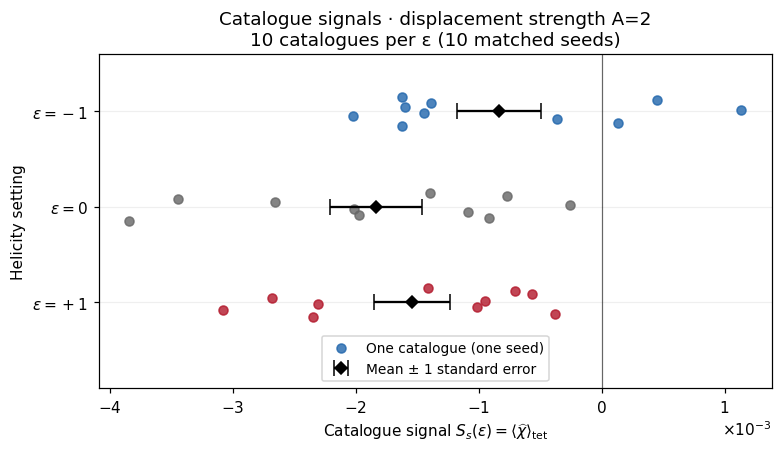

In [5]:
scan = summary["primary_scan"]
paired = scan["rows"]
nulls = [r for r in summary["ensemble_statistics"] if r["case"].startswith("null_") and r["statistic"]=="chi_hat"]
from parity_study.signal_plots import epsilon_comparison, catalogue_signal_figure
comparison = epsilon_comparison(RUN)
if comparison is None:
    display(Markdown("No complete matched ε=−1,0,+1 catalogues saved at the control amplitude yet."))
else:
    display(Markdown(f"**Displacement strength A={comparison['A']:g}; "
                     f"{len(comparison['seeds'])} matched seeds per ε.** "
                     f"A={comparison['A']:g} means an ensemble RMS helical displacement of "
                     f"{comparison['A']:g} in the same length units as the box (L={field['L']:g})."))
    fig = catalogue_signal_figure(comparison)
    save_figure(fig, "catalogue_chi_hat_signal")
    plt.close(fig)
    save_table(comparison["catalogue_rows"],"epsilon_chi_hat_catalogues")
    save_table(comparison["summary_rows"],"epsilon_chi_hat_summary")
    atomic_npz(OUT/"epsilon_chi_hat.npz", **{
        key: comparison[key] for key in ("A","epsilons","seeds","signals","tetrahedron_counts",
                                         "histogram_counts","histogram_edges","histogram_density")})
save_table(paired,"paired_chi_hat")
save_table(nulls,"null_chi_hat")

## 5. Histogram difference: $\epsilon=+1$ minus $\epsilon=-1$

At the same $A$, subtract the negative-helicity histogram from the positive-helicity histogram **in each bin**. Here $s$ labels a matched seed, $N_s$ is the number of matched seeds, and $p_{s,\epsilon}$ is one catalogue's probability density:
$$
\Delta p_s(\widehat\chi)=p_{s,+1}(\widehat\chi)-p_{s,-1}(\widehat\chi),\qquad
\Delta p(\widehat\chi)=\frac{1}{N_s}\sum_s\Delta p_s(\widehat\chi).
$$
The plotted $\Delta p$ is the average difference. **Above zero:** more probability density for $\epsilon=+1$; **below zero:** more for $\epsilon=-1$; **zero:** the two agree in that bin.

**SEM = standard error of the mean**, the estimated uncertainty in this average difference:
$$
\mathrm{SEM}(\widehat\chi)=
\frac{\text{sample standard deviation of }\Delta p_s(\widehat\chi)}{\sqrt{N_s}}.
$$
Each point has error bars $\Delta p\pm1\,\mathrm{SEM}$. It measures uncertainty across the displacement realizations used here; a 1-SEM bar is not a 95% confidence interval. Bins are correlated, so individual excursions alone do not establish a PV detection.

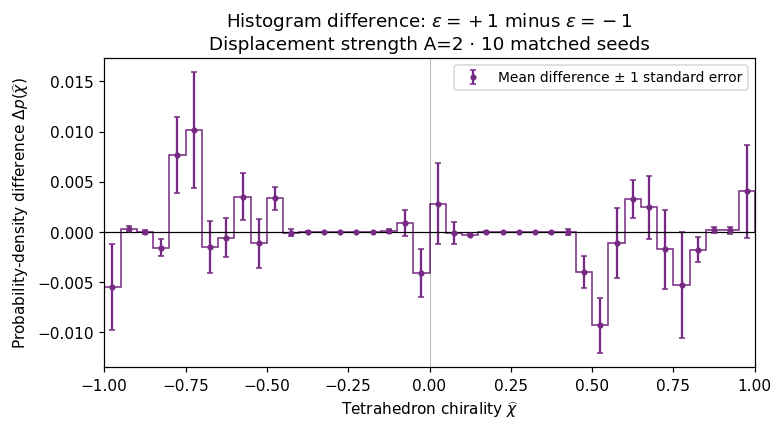

In [6]:
from parity_study.signal_plots import histogram_difference, histogram_difference_figure
difference = None
if comparison is not None:
    difference = histogram_difference(comparison)
    fig = histogram_difference_figure(difference)
    save_figure(fig, "chi_hat_probability_difference")
    plt.close(fig)
    save_table(difference["rows"], "chi_hat_probability_difference")
    atomic_npz(OUT/"chi_hat_probability_difference.npz", **{
        key: difference[key] for key in ("A","seeds","histogram_edges","bin_centers",
                                         "per_seed_difference","mean","sem","mean_covariance")
        if difference[key] is not None})
atomic_json(OUT/"analysis.json",dict(source_run=RUN.name,complete=summary["complete"],
    purpose=config.get("purpose"),primary_statistic="chi_hat",primary_scan=scan,
    density_seed=field.get("density_seed"), ensemble=summary["ensemble"],
    direct_epsilon_comparison=(dict(A=comparison["A"], seeds=comparison["seeds"].tolist(),
        rows=comparison["summary_rows"], histogram_weighting="equal catalogue weights")
        if comparison is not None else None),
    histogram_difference=(dict(definition="p(epsilon=+1) - p(epsilon=-1)",
        A=difference["A"], seeds=difference["seeds"].tolist(),
        uncertainty="Pointwise SEM of matched-seed differences; bins are correlated")
        if difference is not None else None)))

## 6. Can a tetrahedron selection strengthen the signal?

Use the **same reflection-invariant selection** \(B\) for every helicity. A chirality band keeps both signs, for example \(0.50\leq|\widehat\chi|<0.55\). The selected catalogue signal and matched difference are
$$
S_{s,B}(\epsilon)=\frac{1}{N_{s,B}(\epsilon)}\sum_{t\in B}\widehat\chi_{s,t}(\epsilon),\qquad
D_{s,B}=S_{s,B}(+1)-S_{s,B}(-1).
$$
\(N_{s,B}\) is the number selected; \(\overline D_B\) averages the matched differences over seeds.

We explore **three chirality bands, three size groups and three shape groups** at $A=2$. The **reference vertex** has the smallest sum of squared distances to the other three vertices. Sort the lengths of its **three incident edges** as $\ell_1\leq\ell_2\leq\ell_3$. Define size $g=(\ell_1\ell_2\ell_3)^{1/3}/(L/32)$ and shape $r=\ell_1/\ell_3$. Size and shape boundaries divide the original ZA-only catalogue into thirds and are then held fixed.

**Selection used in the catalogue plots (`shape_2`):**
$$
B:\quad 0.6905111410000623\leq r=\frac{\ell_1}{\ell_3}<0.7567675934849439
$$
This keeps about **33% of tetrahedra**, including both signs of $\widehat\chi$. The same bounds apply to every helicity and IC; reflection leaves membership unchanged.

In [7]:
from parity_study.storage import digest
SELECTION = selection_output(OUT)
protocol_path = SELECTION/"protocol.json"
protocol = json.loads(protocol_path.read_text())
assert Path(protocol["discovery_run"]).resolve() == RUN.resolve()
assert protocol["A"] == comparison["A"]
mirror_rows = []
for low, high in [(0.45,0.50),(0.50,0.55)]:
    pos = np.flatnonzero(np.isclose(difference["bin_centers"], (low+high)/2)).item()
    neg = np.flatnonzero(np.isclose(difference["bin_centers"], -(low+high)/2)).item()
    mirror_rows.append(dict(band=f"{low:.2f}–{high:.2f}",
        positive=f"{difference['mean'][pos]:+.5f} ± {difference['sem'][pos]:.5f}",
        negative=f"{difference['mean'][neg]:+.5f} ± {difference['sem'][neg]:.5f}"))
display(Markdown("**Check the mirrored histogram bins (discovery seeds 0–9):**"))
show_table(mirror_rows, [("band","|χ̂| range"),("positive","Δp at positive χ̂ ± SEM"),
                         ("negative","Δp at negative χ̂ ± SEM")])
display(Markdown("The **0.50–0.55 negative-chirality counterpart is consistent with zero**; "
                 "the positive difference is in the neighbouring **−0.50 to −0.45** bin."))
winner = next(c for c in protocol["cuts"] if c["id"] == protocol["primary_selection"])
discovery_primary = next(r for r in protocol["discovery_summaries"] if r["selection"] == winner["id"])
display(Markdown(f"**Frozen primary cut:** {winner['label']}, "
    f"**{winner['low']:.5f} ≤ r < {winner['high']:.5f}**. "
    f"It retains **{100*discovery_primary['retained_fraction']:.1f}%** of tetrahedra. "
    "It was chosen by the largest absolute paired mean divided by its SEM among the nine cuts. "
    "These discovery results guided the choice; confirmation uses fresh seeds."))
selection_checks = json.loads((SELECTION/"transformation_checks.json").read_text())
assert selection_checks["passed"]
display(Markdown("**Selection checks passed:** reflections reverse every selected signal; rotations and translations preserve it."))

**Check the mirrored histogram bins (discovery seeds 0–9):**

|χ̂| range,Δp at positive χ̂ ± SEM,Δp at negative χ̂ ± SEM
0.45–0.50,-0.00404 ± 0.00163,+0.00334 ± 0.00117
0.50–0.55,-0.00936 ± 0.00278,-0.00116 ± 0.00242


The **0.50–0.55 negative-chirality counterpart is consistent with zero**; the positive difference is in the neighbouring **−0.50 to −0.45** bin.

**Frozen primary cut:** Shape third 2, **0.69051 ≤ r < 0.75677**. It retains **33.2%** of tetrahedra. It was chosen by the largest absolute paired mean divided by its SEM among the nine cuts. These discovery results guided the choice; confirmation uses fresh seeds.

**Selection checks passed:** reflections reverse every selected signal; rotations and translations preserve it.

## 7. Does the selected signal persist with 25 realizations?

**25 displacement realizations (seeds 10–34):** 10 retained from the original confirmation, plus 15 newly generated. The selection cut is unchanged. The Gaussian density seed, ZA field and lattice remain fixed.

**Selected catalogue:** average $\widehat\chi$ over the tetrahedra passing the fixed $r=\ell_1/\ell_3$ interval in Section 6 (about 33% retained). 

Each point below is \(\overline D_B\); bars are **95% Student-t intervals across seeds** (wider than one SEM). Purple shows discovery; green shows the confirmation ensemble. A bar crossing zero does not distinguish the two helicities at this interval's confidence level.

The extension was requested after viewing the ten-seed result. The combined p-values are **nominal summaries**; the original ten-seed test remains saved. The added realizations are also summarized separately below. Other cuts are secondary; their p-values are corrected for nine comparisons.

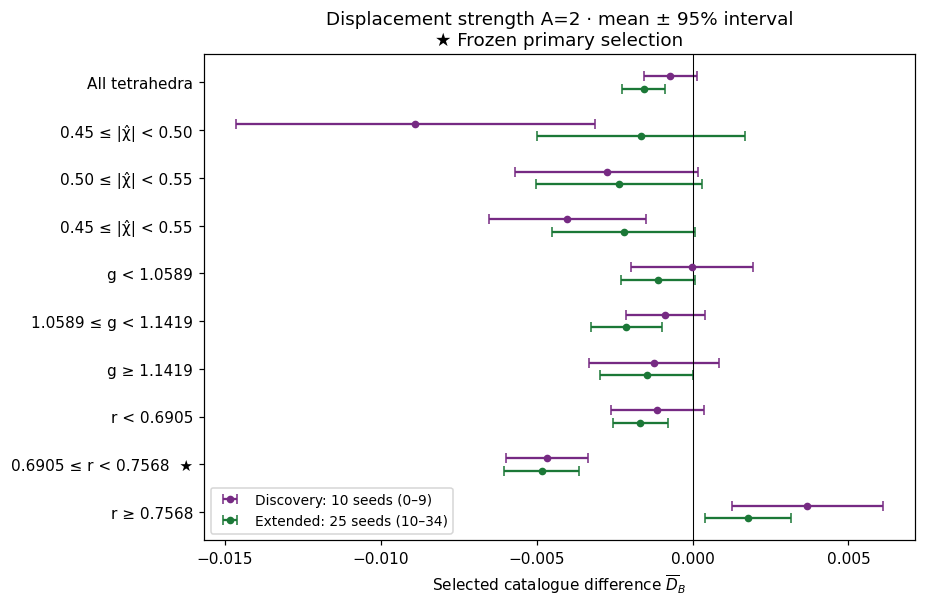

**The frozen selection retains a same-sign response in the 25-realization ensemble.**  
**25 realizations:** D̄_B = **-0.00483 ± 0.00058 (SEM)**; 95% interval **[-0.00604, -0.00363]**; two-sided nominal **p = 1.685e-08**.

**The 15 added realizations alone:** D̄_B = **-0.00462 ± 0.00069 (SEM)**; two-sided **p = 1.028e-05**.

Chirality selection,25-seed D̄_B,SEM,Fraction retained,p (9-cut correction)
0.45 ≤ |χ̂| < 0.50,-0.0016549,0.0016153,0.020515,1
0.50 ≤ |χ̂| < 0.55,-0.0023498,0.0012886,0.079217,0.72635
0.45 ≤ |χ̂| < 0.55,-0.0022057,0.0011098,0.099732,0.5255


**Selected catalogue signals: 25 realizations per helicity.** One coloured dot per catalogue; black diamonds and bars show the mean ± one SEM for ε = −1, 0, +1.

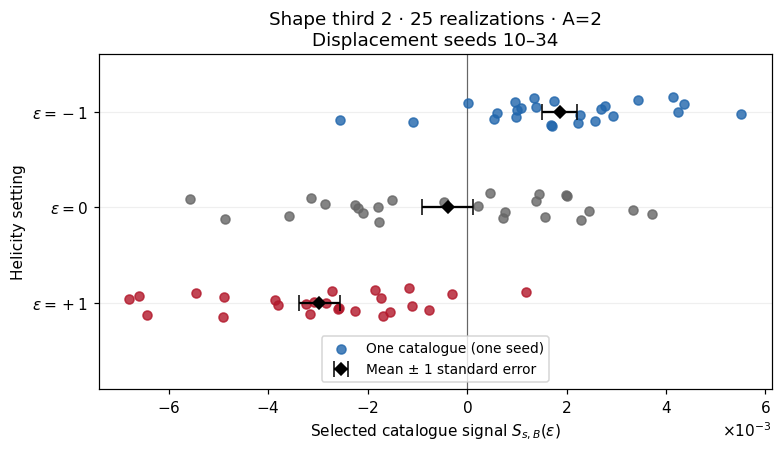

The uncertainty covers **helical-displacement realizations at one fixed density field**. Repeating the frozen cut across independent Gaussian density fields is needed to test whether it generalizes.

[Selection protocol](saved/field_PVdisp/selections/extended_25/protocol.json) · [Catalogue measurements](saved/field_PVdisp/selections/extended_25/confirmation_catalogues.csv) · [Complete selection results](saved/field_PVdisp/selections/extended_25/confirmation.json)

In [8]:
from copy import deepcopy
from parity_study.selections import selection_comparison_figure, selected_catalogue_figure
confirmation_path = SELECTION/"confirmation.json"
if not confirmation_path.exists():
    raise FileNotFoundError("Independent selection confirmation is not finished yet.")
confirmation = json.loads(confirmation_path.read_text())
assert digest(protocol_path) == confirmation["protocol_sha256"]
display_protocol = deepcopy(protocol)
for cut in display_protocol["cuts"]:
    if cut["variable"] in ("size", "shape"):
        symbol = "g" if cut["variable"] == "size" else "r"
        lo, hi = cut["low"], cut["high"]
        cut["label"] = (f"{symbol} < {hi:.4f}" if lo is None else
                        f"{symbol} ≥ {lo:.4f}" if hi is None else f"{lo:.4f} ≤ {symbol} < {hi:.4f}")
fig = selection_comparison_figure(display_protocol, confirmation)
save_figure(fig,"selection_discovery_confirmation")
plt.close(fig)
primary = confirmation["primary"]
display(Markdown(f"**{confirmation['conclusion']}**  \n"
    f"**{primary['n']} realizations:** D̄_B = **{primary['mean']:+.5f} ± {primary['sem']:.5f} (SEM)**; "
    f"95% interval **[{primary['ci95_low']:+.5f}, {primary['ci95_high']:+.5f}]**; "
    f"two-sided {'nominal ' if 'extension' in protocol else ''}**p = {primary['p_two_sided']:.4g}**."))
if "added_seeds_primary" in confirmation:
    added = confirmation["added_seeds_primary"]
    display(Markdown(f"**The {added['n']} added realizations alone:** "
        f"D̄_B = **{added['mean']:+.5f} ± {added['sem']:.5f} (SEM)**; "
        f"two-sided **p = {added['p_two_sided']:.4g}**."))
band_results = [r for r in confirmation["summaries"] if r["selection"].startswith("abs_")]
show_table(band_results,[("label","Chirality selection"),("mean",f"{primary['n']}-seed D̄_B"),
    ("sem","SEM"),("retained_fraction","Fraction retained"),
    ("p_secondary_bonferroni","p (9-cut correction)")])
with np.load(SELECTION/"confirmation.npz") as z:
    confirmed_arrays = {k:z[k] for k in z.files}
display(Markdown(f"**Selected catalogue signals: {len(confirmed_arrays['seeds'])} realizations per helicity.** "
                 "One coloured dot per catalogue; "
                 "black diamonds and bars show the mean ± one SEM for ε = −1, 0, +1."))
fig = selected_catalogue_figure(protocol, confirmed_arrays)
save_figure(fig,"selected_catalogue_chi_hat_signal")
plt.close(fig)
display(Markdown("The uncertainty covers **helical-displacement realizations at one fixed density field**. "
                 "Repeating the frozen cut across independent Gaussian density fields is needed to test whether it generalizes."))
analysis = json.loads((OUT/"analysis.json").read_text())
analysis["selection_test"] = dict(protocol_sha256=confirmation["protocol_sha256"],
    discovery_run=protocol["discovery_run"], confirmation_run=confirmation["confirmation_run"],
    primary_selection=confirmation["primary_selection"], primary=primary,
    primary_confirmed=confirmation["primary_confirmed"],
    same_sign_as_discovery=confirmation["same_sign_as_discovery"])
atomic_json(OUT/"analysis.json", analysis)
selection_link = "saved/field_PVdisp/" + SELECTION.relative_to(OUT).as_posix()
display(Markdown(f"[Selection protocol]({selection_link}/protocol.json) · "
                 f"[Catalogue measurements]({selection_link}/confirmation_catalogues.csv) · "
                 f"[Complete selection results]({selection_link}/confirmation.json)"))

## 8. Does the signal persist across independent Gaussian initial conditions?

**25 independent initial conditions (seeds 100–124), at displacement strength A=2.** Each realization draws a new Gaussian density/ZA field and an independent helical pair. Within a realization, ε=−1, 0, +1 share those fields and the same particle lattice.

**Selected catalogue:** average $\widehat\chi$ over the tetrahedra passing the same fixed $r=\ell_1/\ell_3$ interval in Section 6 (about 33% retained). The cut and sample size were fixed before generation. Each IC supplies one matched difference, $D_{s,B}=S_{s,B}(+1)-S_{s,B}(-1)$. **SEM and 95% intervals now include variation in both density and displacement**, with one observation per IC. The fixed-IC and independent-IC estimates are shown separately.

**Audit passed:** 25 distinct density/ZA fields and helical pairs; all 100 catalogue maps match their saved fields.

**The frozen shape selection replicates the helicity response across independent Gaussian ICs.**  
Selected mean difference **D̄_B = -0.00405 ± 0.00056 (SEM)**; 95% interval **[-0.00522, -0.00289]**; two-sided **p = 1.965e-07**. The unchanged cut retains **33.3%** of tetrahedra.

Selection,Independent ICs,Mean D̄_B,SEM,95% lower,95% upper
All tetrahedra,25,-0.00094588,0.00025434,-0.0014708,-0.00042095
Shape third 2,25,-0.004055,0.00056375,-0.0052185,-0.0028914


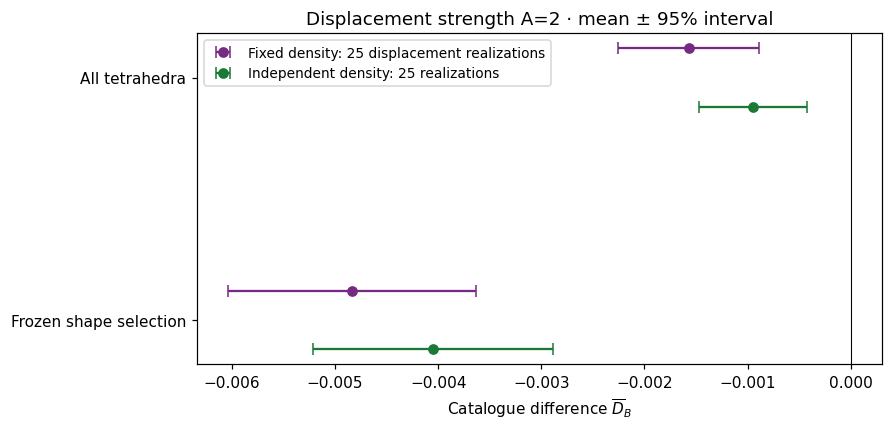

The primary test uses the one frozen shape cut: two-sided paired Student-t, p < 0.05 and the same sign as discovery. The all-tetrahedron baseline is descriptive. The earlier fixed-IC 25-seed interval remains a nominal summary of its extended sample.

In [9]:
from parity_study.paths import independent_ic_output
from parity_study.independent_ics import comparison_figure
IC_OUT = independent_ic_output(OUT)
if IC_OUT is None:
    raise FileNotFoundError("No completed independent-IC report is active")
ic_protocol_path = IC_OUT/"protocol.json"
ic_protocol = json.loads(ic_protocol_path.read_text())
ic_report = json.loads((IC_OUT/"confirmation.json").read_text())
assert digest(ic_protocol_path) == ic_report["protocol_sha256"]
ic_primary = ic_report["primary"]
ic_audit = ic_report["independent_ic_audit"]
assert ic_audit["passed"]
display(Markdown(f"**Audit passed:** {ic_audit['independent_initial_conditions']} distinct density/ZA fields "
                 f"and helical pairs; all {ic_audit['checked_catalogues']} catalogue maps match their saved fields."))
display(Markdown(f"**{ic_report['conclusion']}**  \n"
    f"Selected mean difference **D̄_B = {ic_primary['mean']:+.5f} ± {ic_primary['sem']:.5f} (SEM)**; "
    f"95% interval **[{ic_primary['ci95_low']:+.5f}, {ic_primary['ci95_high']:+.5f}]**; "
    f"two-sided **p = {ic_primary['p_two_sided']:.4g}**. "
    f"The unchanged cut retains **{100*ic_primary['retained_fraction']:.1f}%** of tetrahedra."))
show_table(ic_report["summaries"], [("label","Selection"),("n","Independent ICs"),
    ("mean","Mean D̄_B"),("sem","SEM"),("ci95_low","95% lower"),("ci95_high","95% upper")])
fig = comparison_figure(ic_protocol, ic_report)
save_figure(fig, "independent_ic_selection_comparison")
plt.close(fig)
display(Markdown("The primary test uses the one frozen shape cut: two-sided paired Student-t, "
                 "p < 0.05 and the same sign as discovery. The all-tetrahedron baseline is descriptive. "
                 "The earlier fixed-IC 25-seed interval remains a nominal summary of its extended sample."))

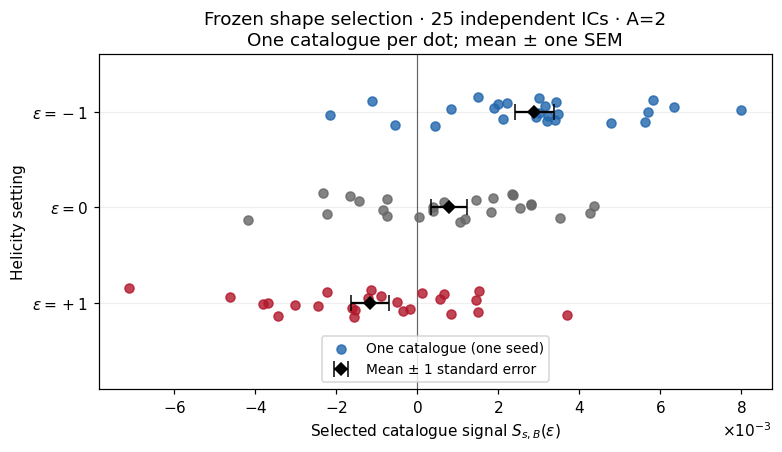

Selected control,Mean S_B,SEM,95% lower,95% upper
"ε = 0, A = 2",0.00078716,0.00043623,-0.00011317,0.0016875
"ZA only, A = 0",0.00039099,0.00054424,-0.00073226,0.0015142


Controls are descriptive checks of the selected signal around zero. This experiment uses initial-condition catalogues with the same toy spectrum, lattice and resolution; gravitational evolution is a later test.

[Frozen protocol](saved/field_PVdisp/independent_ic_25/protocol.json) · [Catalogue measurements](saved/field_PVdisp/independent_ic_25/confirmation_catalogues.csv) · [Independent-IC results](saved/field_PVdisp/independent_ic_25/confirmation.json)

In [10]:
with np.load(IC_OUT/"confirmation.npz") as z:
    ic_arrays = {k:z[k] for k in z.files}
fig = selected_catalogue_figure(ic_protocol, ic_arrays)
fig.axes[0].set_title(f"Frozen shape selection · {len(ic_arrays['seeds'])} independent ICs · A={ic_protocol['A']:g}\n"
                     "One catalogue per dot; mean ± one SEM")
save_figure(fig, "independent_ic_selected_catalogue_signal")
plt.close(fig)
ic_control = next(row for row in ic_report["controls"] if row["selection"] == ic_protocol["primary_selection"])
control_rows = [dict(control=name, **ic_control[key]) for name,key in
                [("ε = 0, A = 2", "epsilon0"), ("ZA only, A = 0", "za_only")]]
show_table(control_rows, [("control","Selected control"),("mean","Mean S_B"),("sem","SEM"),
                         ("ci95_low","95% lower"),("ci95_high","95% upper")])
display(Markdown("Controls are descriptive checks of the selected signal around zero. "
                 "This experiment uses initial-condition catalogues with the same toy spectrum, lattice "
                 "and resolution; gravitational evolution is a later test."))
ic_link = "saved/field_PVdisp/" + IC_OUT.relative_to(OUT).as_posix()
display(Markdown(f"[Frozen protocol]({ic_link}/protocol.json) · "
                 f"[Catalogue measurements]({ic_link}/confirmation_catalogues.csv) · "
                 f"[Independent-IC results]({ic_link}/confirmation.json)"))

[Figures](saved/field_PVdisp/figures/) · [Tables and saved meshes](saved/field_PVdisp/) · [Run configuration](saved/20261121_mesh_ic_L1000_N256_fixedIC_10/config.json)